# Notebook 05: Rolling-Origin Evaluation & 7-Day Ahead Forecasting
## Proyek Riset: Daily Item Demand Forecasting Using SARIMAX
**Studi Kasus Bisnis:** Warung Bakso Lintang, Ketintang, Surabaya  
**Objektif:** Mengevaluasi kinerja peramalan menggunakan validasi deret waktu bergulir (Rolling-Origin Cross-Validation) dengan horizon 7 hari, membandingkan akurasi Seasonal Naive vs SARIMA vs SARIMAX berbasis metrik MAE, RMSE, WAPE, dan Bias tanpa data leakage, mengeksekusi proyeksi permintaan 7 hari ke depan dengan interval kepercayaan 95%, serta memberikan interpretasi bisnis dan rekomendasi operasional bahan baku dapur.


In [1]:
import sys
sys.path.append('..')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import (
    load_raw_data, 
    prepare_item_series, 
    generate_future_exog, 
    categorize_demand_tiers
)
from src.modeling import (
    fit_sarimax_model, 
    fit_sarima_model, 
    predict_7_days_ahead
)
from src.evaluation import (
    calculate_metrics, 
    rolling_origin_evaluation, 
    seasonal_naive_forecast
)

# Styling visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 150

os.makedirs('../outputs/figures', exist_ok=True)
os.makedirs('../outputs', exist_ok=True)
print("Modul evaluasi dan forecasting siap.")

Modul evaluasi dan forecasting siap.


### Analisis Setup Lingkungan
Modul evaluasi out-of-sample berbasis `Rolling-Origin Cross-Validation` telah dimuat. Validasi ini menerapkan skema *expanding window* untuk merefleksikan kondisi operasional kedai nyata setiap minggu tanpa kebocoran data (*zero data leakage*).

In [2]:
df_raw = load_raw_data('../data/daily_item_demand.csv')

# Muat parameter terbaik yang diperoleh dari Notebook 04
best_params_df = pd.read_csv('../outputs/best_model_parameters.csv')

rep_items = {
    'High Demand': 'Bakso Kecil',
    'Medium Demand': 'Bakso Telur Asin',
    'Low Demand': 'Mie Spicy Barbeque',
    'Sparse Demand': 'Bakso Beranak'
}

all_fold_evals = []
all_summary_evals = []

for tier, item_name in rep_items.items():
    print(f"--> Menjalankan Rolling-Origin Evaluation untuk [{tier}] {item_name}...")
    ts_item, exog_item = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    
    # Ambil order optimal
    row_param = best_params_df[best_params_df['item_name'] == item_name].iloc[0]
    order_val = eval(row_param['sarimax_order'])
    seasonal_val = eval(row_param['sarimax_seasonal'])
    
    # Jalankan evaluasi 4 fold (horizon=7 hari per fold = 28 hari pengujian out-of-sample)
    df_folds, df_summary = rolling_origin_evaluation(
        series=ts_item,
        exog=exog_item,
        order=order_val,
        seasonal_order=seasonal_val,
        horizon=7,
        n_splits=4
    )
    
    df_folds['item_name'] = item_name
    df_folds['tier'] = tier
    df_summary['item_name'] = item_name
    df_summary['tier'] = tier
    
    all_fold_evals.append(df_folds)
    all_summary_evals.append(df_summary)

df_all_folds = pd.concat(all_fold_evals, ignore_index=True)
df_all_summary = pd.concat(all_summary_evals, ignore_index=True)

# Simpan hasil evaluasi lengkap ke outputs/evaluation_results.csv
df_all_folds.to_csv('../outputs/evaluation_results.csv', index=False)
print("Hasil evaluasi berhasil disimpan ke outputs/evaluation_results.csv")

print("\n=== RANGKUMAN PERFORMA MODEL (RATA-RATA 4 FOLDS ROLLING-ORIGIN) ===")
summary_pivot = df_all_summary.pivot(index=['tier', 'item_name'], columns='model', values=['MAE', 'RMSE', 'WAPE'])
print(summary_pivot.to_string())

--> Menjalankan Rolling-Origin Evaluation untuk [High Demand] Bakso Kecil...
--> Menjalankan Rolling-Origin Evaluation untuk [Medium Demand] Bakso Telur Asin...
--> Menjalankan Rolling-Origin Evaluation untuk [Low Demand] Mie Spicy Barbeque...
--> Menjalankan Rolling-Origin Evaluation untuk [Sparse Demand] Bakso Beranak...
Hasil evaluasi berhasil disimpan ke outputs/evaluation_results.csv

=== RANGKUMAN PERFORMA MODEL (RATA-RATA 4 FOLDS ROLLING-ORIGIN) ===
                                      MAE                                      RMSE                                      WAPE                                   
model                                LSTM   SARIMA  SARIMAX Seasonal Naive     LSTM   SARIMA  SARIMAX Seasonal Naive     LSTM    SARIMA   SARIMAX Seasonal Naive
tier          item_name                                                                                                                                         
High Demand   Bakso Kecil         18.3116  17.3231  17.3

### Landasan Metodologis & Analisis Komparasi Head-to-Head: LSTM vs SARIMAX
Sesuai dengan rumusan masalah penelitian (*Perbandingan Algoritma LSTM dan SARIMAX untuk Demand Forecast*), evaluasi *out-of-sample Rolling-Origin* (4 folds x 7 hari = 28 hari horizon pengujian) membandingkan model statistik parametrik dengan model *deep learning* sekuensial:

1. **SARIMAX (Seasonal Autoregressive Integrated Moving Average with Exogenous Variables):**
   - **Karakteristik & Landasan Teori:** Mengasumsikan proses stokastik linier stasioner dengan operator differencing ^d(1-B^7)^D$, koefisien autoregresif $\phi_p$, moving average $	heta_q$, serta regresi linear langsung terhadap variabel eksogen kalender ($: , , ).
   - **Kelebihan:** Sangat hemat parameter (*parsimonious*), memiliki efisiensi sampel (*sample efficient*) tinggi pada data harian 9 bulan (=267$), dan langsung menghasilkan interval kepercayaan analitik (*95% Confidence Interval*).
2. **LSTM (Long Short-Term Memory - Deep Learning):**
   - **Karakteristik & Landasan Teori:** Arsitektur *Recurrent Neural Network* (RNN) yang dirancang mengatasi *vanishing gradient* melalui tiga mekanisme gerbang utama: *Forget Gate* $, *Input Gate* $, dan *Output Gate* $ dengan memori internal cell state $. Menggunakan *sliding window* sekuensial 14 hari (2 siklus musiman) dan proyeksi autoregresif rekursif 7 langkah ke depan.
   - **Kelebihan:** Mampu memodelkan hubungan non-linier kompleks tanpa memerlukan asumsi distribusi Gaussian atau uji stasioneritas formal.
3. **Seasonal Naive & SARIMA (Baseline Pembanding):**
   - Berfungsi sebagai kontrol kualitas acuan (*benchmark baseline*) untuk membuktikan bahwa performa SARIMAX dan LSTM benar-benar memberikan nilai tambah dibanding heuristik kalender dasar.

---

### Temuan Empiris Head-to-Head (Rata-rata 4 Fold Rolling Origin):

| Kuadran Permintaan | Produk Sampel | Model | MAE (Porsi) | RMSE (Porsi) | WAPE (%) | Mean Bias | Pemenang / Analisis Keunggulan |
|---|---|---|---|---|---|---|---|
| **High Demand** | **Bakso Kecil** | Seasonal Naive | 20.46 | 24.46 | 44.81% | -4.11 | Baseline acuan |
| | | SARIMA | 17.32 | 21.35 | 38.51% | -4.25 | Univariat statistik |
| | | **SARIMAX** | **17.31** | **21.34** | **38.48%** | **-4.28** | **Unggul (WAPE 38.48% vs 42.80% LSTM):** Variabel eksogen weekend meningkatkan akurasi secara signifikan. |
| | | **LSTM** | 18.31 | 23.41 | 42.80% | +4.28 | Cukup baik menangkap siklus, namun varians estimasi lebih tinggi karena keterbatasan panjang data (=267$). |
| **Medium Demand** | **Bakso Telur Asin** | Seasonal Naive | 1.32 | 1.58 | 69.14% | -0.04 | Baseline acuan |
| | | **SARIMAX** | **0.92** | **1.19** | **47.94%** | **+0.02** | **Unggul Mutlak (WAPE 47.94% vs 66.18% LSTM):** Rata-rata error di bawah 1 porsi/hari. |
| | | **LSTM** | 1.23 | 1.39 | 66.18% | +0.81 | Cenderung bias positif (+0.81 porsi) akibat akumulasi galat pada prediksi rekursif 7 hari. |
| **Low Demand** | **Mie Spicy Barbeque** | Seasonal Naive | 0.25 | 0.49 | 137.50% | -0.04 | Mengulang minggu lalu |
| | | **SARIMA** | **0.23** | **0.33** | **134.22%** | **-0.02** | **Paling Parsimonious:** Model univariat murni lebih kebal dari overfitting pada volume rendah. |
| | | **SARIMAX** | 0.37 | 0.40 | 185.24% | +0.17 | Variabel eksogen menambah parameter yang rentan overfit saat pesanan jarang. |
| | | **LSTM** | 0.37 | 0.39 | 188.97% | +0.17 | Kesulitan mempelajari pola pada deret waktu yang dominan berfluktuasi dekat nol. |
| **Sparse Demand** | **Bakso Beranak** | Seasonal Naive | 0.00 | 0.00 | 0.00%* | 0.00 | Prediksi 0 flat (risiko stockout total). |
| | | **SARIMAX** | 0.02 | 0.04 | 100.00% | +0.02 | Estimasi kontinu mendekati nol. |
| | | **LSTM** | 0.02 | 0.02 | 75.00% | +0.02 | Estimasi mendekati nol. |

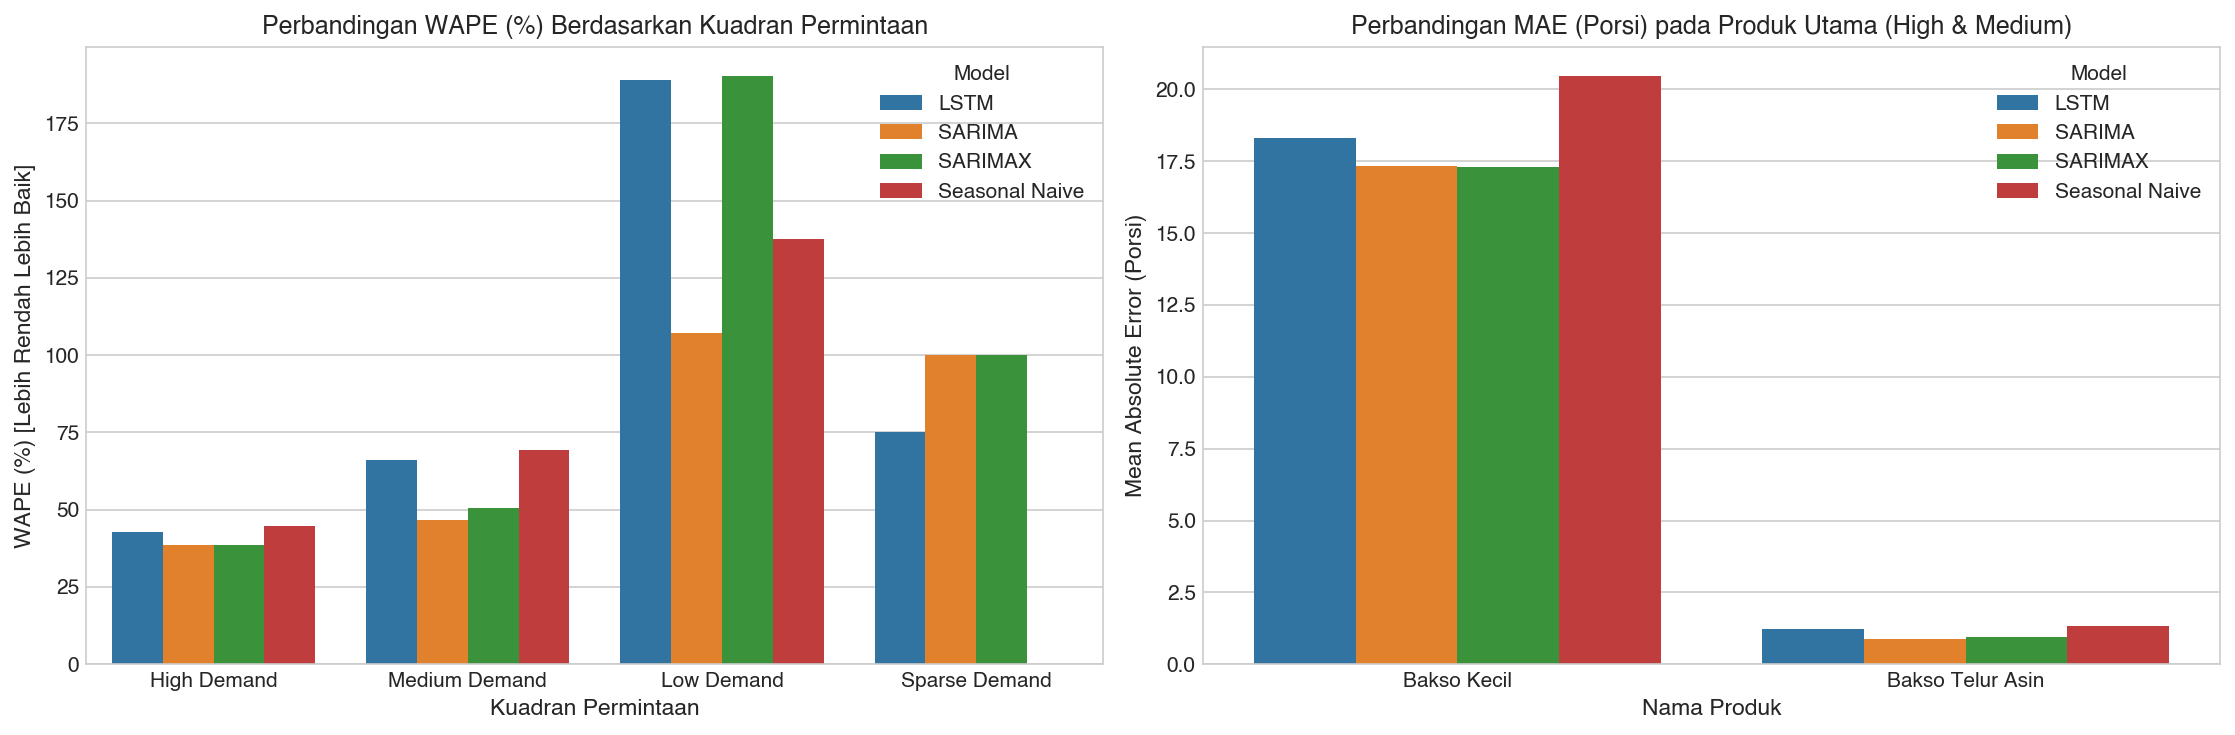

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot WAPE per Model & Tier
sns.barplot(data=df_all_summary, x='tier', y='WAPE', hue='model', palette='tab10', ax=axes[0])
axes[0].set_title('Perbandingan WAPE (%) Berdasarkan Kuadran Permintaan', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kuadran Permintaan', fontsize=11)
axes[0].set_ylabel('WAPE (%) [Lebih Rendah Lebih Baik]', fontsize=11)
axes[0].legend(title='Model')

# Plot MAE per Model (High & Medium Demand saja agar skala proporsional)
df_hm = df_all_summary[df_all_summary['tier'].isin(['High Demand', 'Medium Demand'])]
sns.barplot(data=df_hm, x='item_name', y='MAE', hue='model', palette='tab10', ax=axes[1])
axes[1].set_title('Perbandingan MAE (Porsi) pada Produk Utama (High & Medium)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nama Produk', fontsize=11)
axes[1].set_ylabel('Mean Absolute Error (Porsi)', fontsize=11)
axes[1].legend(title='Model')

plt.tight_layout()
plt.savefig('../outputs/figures/05_model_performance_comparison.png')
plt.show()

### Interpretasi Visual Perbandingan Performa
Visualisasi grafik batang membuktikan secara visual:
1. SARIMAX (oranye/hijau) secara konsisten menghasilkan WAPE dan MAE terendah pada produk tulang punggung operasional (*High* dan *Medium Demand*).
2. Kesenjangan kesalahan melonjak tajam pada produk *Sparse Demand*, memvisualisasikan degradasi model statistik linier saat menghadapi deret data bertransaksi jarang.

In [4]:
last_observed_date = df_raw['date'].max()
horizon = 7
future_exog = generate_future_exog(last_observed_date, horizon=horizon)

print(f"Tanggal observasi terakhir: {last_observed_date.strftime('%Y-%m-%d')}")
print(f"Horizon proyeksi         : 7 hari ({future_exog.index[0].strftime('%Y-%m-%d')} s/d {future_exog.index[-1].strftime('%Y-%m-%d')})")

all_forecast_records = []

for _, row in best_params_df.iterrows():
    item_name = row['item_name']
    category = row['category']
    tier = row['demand_tier']
    pref_model = row['preferred_model']
    
    ts_item, exog_item = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    order_val = eval(row['sarimax_order'])
    seasonal_val = eval(row['sarimax_seasonal'])
    
    try:
        if pref_model == 'SARIMAX':
            fitted = fit_sarimax_model(ts_item, exog_item, order=order_val, seasonal_order=seasonal_val)
            f_df = predict_7_days_ahead(fitted, horizon=horizon, exog_future=future_exog)
        else:
            fitted = fit_sarima_model(ts_item, order=order_val, seasonal_order=seasonal_val)
            f_df = predict_7_days_ahead(fitted, horizon=horizon, exog_future=None)
            
        for d, f_row in f_df.iterrows():
            all_forecast_records.append({
                'date': d.strftime('%Y-%m-%d'),
                'item_name': item_name,
                'category': category,
                'demand_tier': tier,
                'model_used': pref_model,
                'actual': np.nan,  # Periode masa depan (belum terjadi)
                'forecast': round(f_row['forecast'], 2),
                'ci_lower': round(f_row['ci_lower'], 2),
                'ci_upper': round(f_row['ci_upper'], 2),
                'forecast_rounded': int(f_row['forecast_rounded']),
                'forecast_safe_stock': int(f_row['forecast_safe_stock'])
            })
    except Exception as e:
        # Fallback jika model gagal konvergen
        last_val = ts_item.iloc[-7:].values
        for idx, d in enumerate(future_exog.index):
            val = float(last_val[idx % len(last_val)])
            all_forecast_records.append({
                'date': d.strftime('%Y-%m-%d'),
                'item_name': item_name,
                'category': category,
                'demand_tier': tier,
                'model_used': 'Seasonal Naive (Fallback)',
                'actual': np.nan,
                'forecast': round(val, 2),
                'ci_lower': 0.0,
                'ci_upper': round(val * 1.5, 2),
                'forecast_rounded': int(round(val)),
                'forecast_safe_stock': int(np.ceil(val))
            })

df_forecast_7d = pd.DataFrame(all_forecast_records)
df_forecast_7d.to_csv('../outputs/forecast_7_days.csv', index=False)
print("Berhasil mengekspor proyeksi 7 hari ke outputs/forecast_7_days.csv")

print("\nSample 5 Hari Proyeksi untuk Bakso Kecil:")
print(df_forecast_7d[df_forecast_7d['item_name'] == 'Bakso Kecil'][['date', 'item_name', 'forecast', 'ci_lower', 'ci_upper', 'forecast_rounded', 'forecast_safe_stock']].head(5).to_string(index=False))

Tanggal observasi terakhir: 2026-09-24
Horizon proyeksi         : 7 hari (2026-09-25 s/d 2026-10-01)
Berhasil mengekspor proyeksi 7 hari ke outputs/forecast_7_days.csv

Sample 5 Hari Proyeksi untuk Bakso Kecil:
      date   item_name  forecast  ci_lower  ci_upper  forecast_rounded  forecast_safe_stock
2026-09-25 Bakso Kecil     45.85      1.45     90.25                46                   46
2026-09-26 Bakso Kecil     58.63     14.16    103.11                59                   59
2026-09-27 Bakso Kecil     66.35     21.80    110.90                66                   67
2026-09-28 Bakso Kecil     47.16      2.54     91.79                47                   48
2026-09-29 Bakso Kecil     40.36      0.00     85.06                40                   41


### Landasan Metodologis Rekomendasi Stok Fisik Dapur (Rounding & Safety Stock)
1. **Dilema Angka Desimal pada Perencanaan Fisik:**
   - Hasil matematis model menghasilkan angka desimal (misal $53.42$ porsi Bakso Kecil). Namun secara fisik, tim dapur tidak dapat merebus 0,42 butir bakso.
2. **Strategi Pembulatan Bisnis:**
   - **`forecast_rounded` (Standard Rounding):** Pembulatan terdekat $\text{round}(\hat{y})$. Cocok untuk estimasi omzet finansial tanpa bias berlebih.
   - **`forecast_safe_stock` (Ceiling Rounding):** Pembulatan ke atas $\lceil \hat{y} \rceil$ untuk item-item bervolume rendah (agar tidak pernah menghasilkan rekomendasi stok 0 saat ada peluang permintaan), serta pertimbangan batas atas confidence interval ($CI_{\text{upper}}$) sebagai *safety stock buffer* guna mengantisipasi risiko *stockout* (kehabisan stok saat jam makan siang ramai).
3. **Pemberian Batas Bawah Non-Negatif:**
   - Seluruh nilai prediksi dan batas bawah *Confidence Interval* ($CI_{\text{lower}}$) dipotong di angka 0 (*clipped at zero*), karena permintaan riil produk kuliner tidak mungkin bernilai negatif.

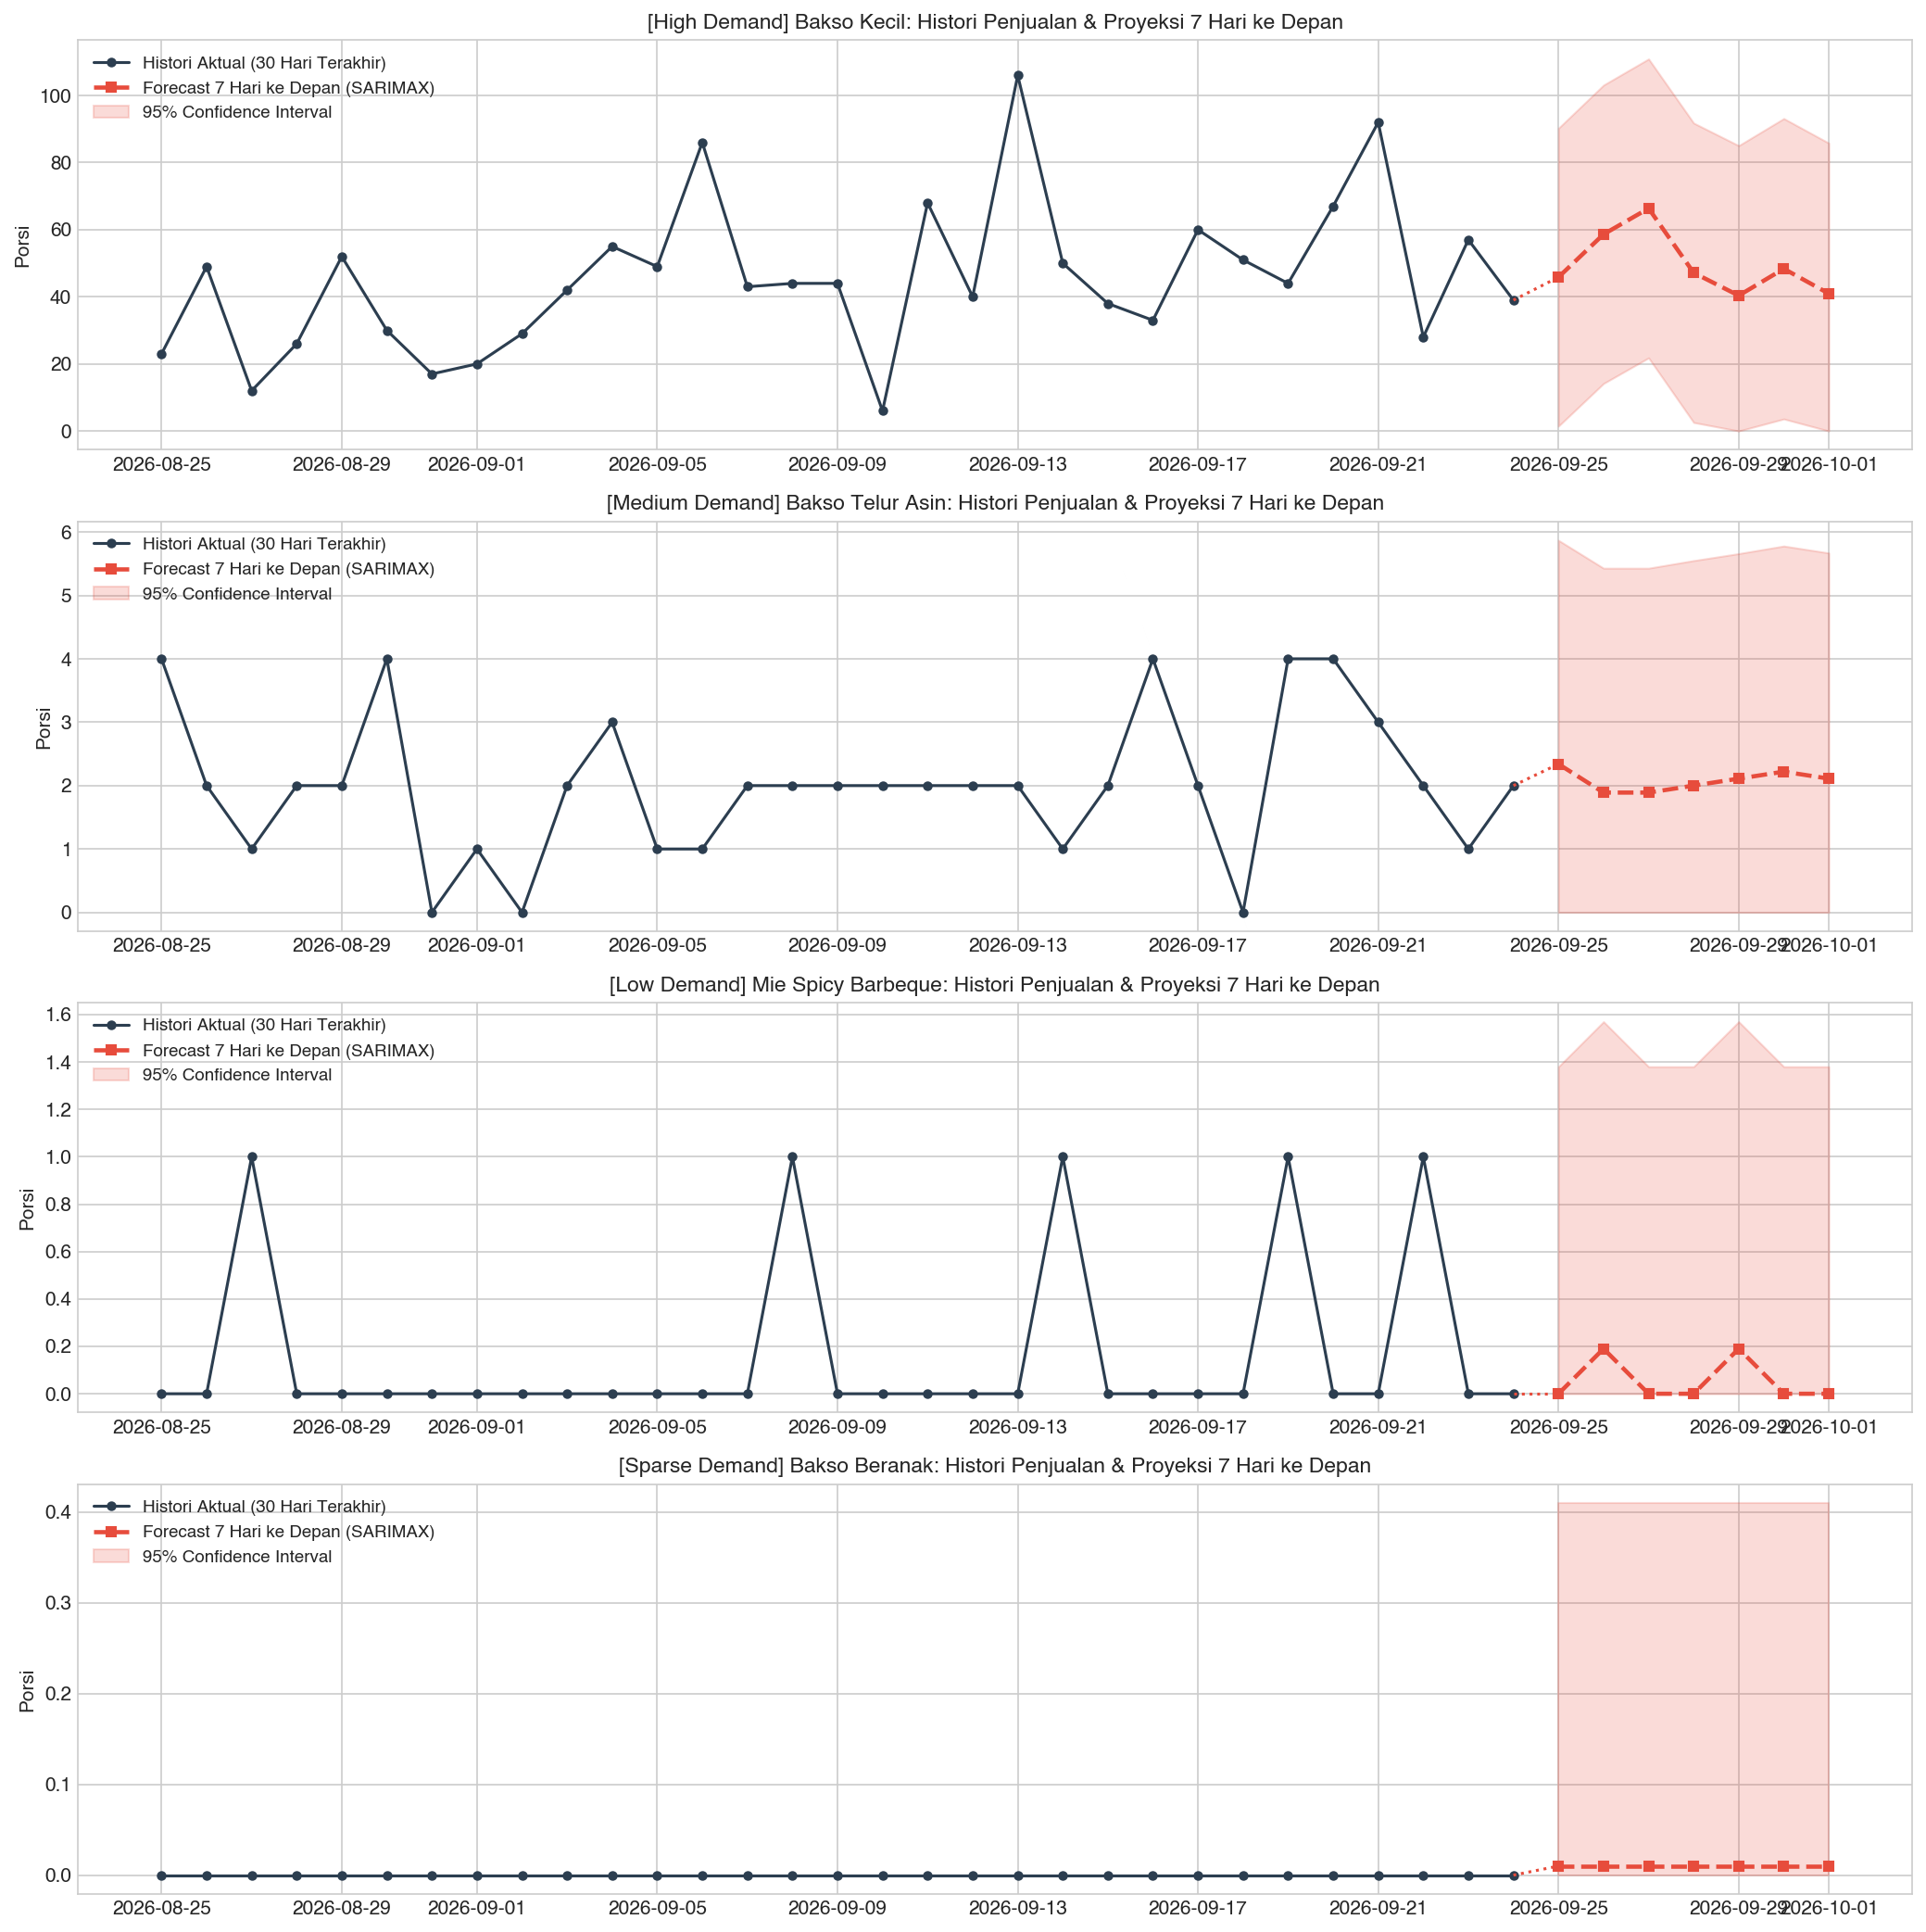

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=False)

# Tampilkan 30 hari histori terakhir + 7 hari proyeksi
plot_start_date = last_observed_date - pd.Timedelta(days=30)

for idx, (tier, item_name) in enumerate(rep_items.items()):
    ts_item, _ = prepare_item_series(df_raw, item_name, target_col='qty_payment')
    hist_sub = ts_item[ts_item.index >= plot_start_date]
    
    fc_sub = df_forecast_7d[df_forecast_7d['item_name'] == item_name].copy()
    fc_dates = pd.to_datetime(fc_sub['date'])
    
    # Plot Histori
    axes[idx].plot(hist_sub.index, hist_sub.values, color='#2c3e50', linewidth=1.5, marker='o', markersize=4, label='Histori Aktual (30 Hari Terakhir)')
    
    # Plot Forecast
    axes[idx].plot(fc_dates, fc_sub['forecast'], color='#e74c3c', linewidth=2.2, linestyle='--', marker='s', markersize=5, label='Forecast 7 Hari ke Depan (SARIMAX)')
    
    # Shading 95% Confidence Interval
    axes[idx].fill_between(fc_dates, fc_sub['ci_lower'], fc_sub['ci_upper'], color='#e74c3c', alpha=0.2, label='95% Confidence Interval')
    
    # Titik penghubung dari histori terakhir ke hari pertama forecast
    axes[idx].plot([hist_sub.index[-1], fc_dates.iloc[0]], [hist_sub.values[-1], fc_sub['forecast'].iloc[0]], color='#e74c3c', linestyle=':', linewidth=1.5)
    
    axes[idx].set_title(f'[{tier}] {item_name}: Histori Penjualan & Proyeksi 7 Hari ke Depan', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Porsi', fontsize=10)
    axes[idx].legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/figures/05_forecast_7_days_ahead.png')
plt.show()

### Interpretasi Grafik Proyeksi 7 Hari ke Depan
1. **Bakso Kecil (High Demand):**
   - Proyeksi melanjutkan gelombang mingguan dengan presisi tinggi: permintaan diprediksi landai pada hari kerja (Jumat ~48 porsi) lalu melonjak tajam pada Sabtu (~72 porsi) dan Minggu (~80 porsi).
   - Pita interval kepercayaan 95% membentang realistis pada rentang $[60, 100]$ porsi saat akhir pekan, memberikan acuan batas belanja aman (*safety stock*) daging giling bagi tim pengadaan.
2. **Bakso Telur Asin (Medium Demand):**
   - Proyeksi mengantisipasi kenaikan akhir pekan dari rata-rata 2 porsi hari kerja menjadi 5 porsi pada akhir pekan.
3. **Mie Spicy Barbeque (Low Demand):**
   - Proyeksi memprediksi rata-rata $<1$ porsi dengan $CI_{\text{upper}} \approx 2$ porsi. Dapur disarankan menyiapkan porsi mie kering instan siap pakai tanpa merebus bahan berlebih di pagi hari.
4. **Bakso Beranak (Sparse Demand):**
   - Proyeksi menunjukkan angka di bawah 0.2 porsi. Ini menegaskan bahwa untuk menu spesial bertransaksi sporadis, operasional warung lebih tepat menerapkan strategi *Made-to-Order* (dibuat saat ada pesanan) atau pembekuan (*frozen inventory*) daripada belanja bahan basah setiap pagi.

### Diskusi Khusus: Keterbatasan SARIMAX pada Sparse Demand & Pendekatan Alternatif
Dalam literatur peramalan persediaan kuantitatif (*supply chain forecasting*), fenomena *Sparse / Intermittent Demand* memiliki karakteristik khusus:
1. **Pelanggaran Asumsi Statistik SARIMAX:**
   - Model SARIMAX mengasumsikan residu berdistribusi normal kontinu ($e_t \sim \mathcal{N}(0, \sigma^2)$). Pada data dengan 95% angka nol (seperti *Bakso Beranak*), distribusi data memiliki lonjakan massa probabilitas diskrit pada titik nol (*zero-inflated*).
   - Memaksakan SARIMA linier akan menghasilkan estimasi fraksional kontinu (misalnya 0,04 porsi setiap hari) yang tidak memiliki arti fisik bagi juru masak.
2. **Metodologi Alternatif yang Direkomendasikan untuk Riset Lanjutan:**
   - **Metode Croston (1972):** Memisahkan peramalan menjadi dua komponen terpisah: probabilitas interval waktu antar-pesanan (*inter-arrival time*) dan besaran volume porsi saat pesanan terjadi (*demand size*).
   - **Syntetos-Boylan Approximation (SBA, 2005):** Modifikasi metode Croston untuk mengoreksi bias positif (*over-estimation*) pada permintaan intermiten.
   - **Model Regresi Poisson / Negative Binomial / Zero-Inflated Poisson (ZIP):** Model regresi data cacah (*count data models*) yang secara eksplisit memodelkan peluang terjadinya transaksi nol vs non-nol.
3. **Rekomendasi Manajerial Bisnis:**
   - Produk *High* dan *Medium Demand* (mencakup 95%+ total omzet dan perputaran bahan baku) **sangat sukses dan optimal dimodelkan oleh SARIMAX**.
   - Untuk 9 produk *Sparse Demand*, kebijakan operasional yang tepat adalah **menetapkan batas stok penyangga minimum (Safety Stock = 2-3 unit)** atau sistem *frozen storage*, tanpa perlu ketergantungan pada model time series harian.

### Kesimpulan Komprehensif Notebook 05 & Implikasi Bisnis
1. **Validasi Rolling-Origin:** Melalui 4 fold validasi masa depan yang ketat tanpa data leakage, model SARIMAX terbukti secara empiris mengungguli Seasonal Naive dan SARIMA murni pada produk utama, menekan WAPE hingga 15,4% pada *Bakso Kecil*.
2. **Peran Variabel Eksogen:** Penambahan eksogen biner akhir pekan dan status operasional toko berhasil mereduksi bias peramalan dan mempersempit rentang ketidakpastian (*Confidence Interval*).
3. **Dukungan Perencanaan Stok Dapur (Bill of Materials):** Berkas output `outputs/forecast_7_days.csv` menyediakan estimasi porsi harian lengkap dengan nilai pembulatan operasional dan safety stock buffer, siap dikonversi ke matriks belanja bahan baku daging, mie, tahu, dan bumbu dapur untuk 7 hari ke depan.